# European Union inflation replication: 2007–2025
Guardian news is combined with Eurostat EU-27 macroeconomic data. All news and macro predictors are lagged one month; models are estimated through December 2021 and evaluated over 2022–2025.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'modelling').is_dir())
DATASET = ROOT / 'data/processed/europe/eu27_guardian_monthly_experiment.csv'
RESULTS = ROOT / 'data/processed/europe/eu27_guardian_results_2022_2025.json'
data = pd.read_csv(DATASET, parse_dates=['Date'])
results = json.loads(RESULTS.read_text(encoding='utf-8'))
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

## Data coverage

,EU-27 replication
First month,2007-01-01
Last month,2025-12-01
Months,228
Guardian articles,29080
Scored test months,48


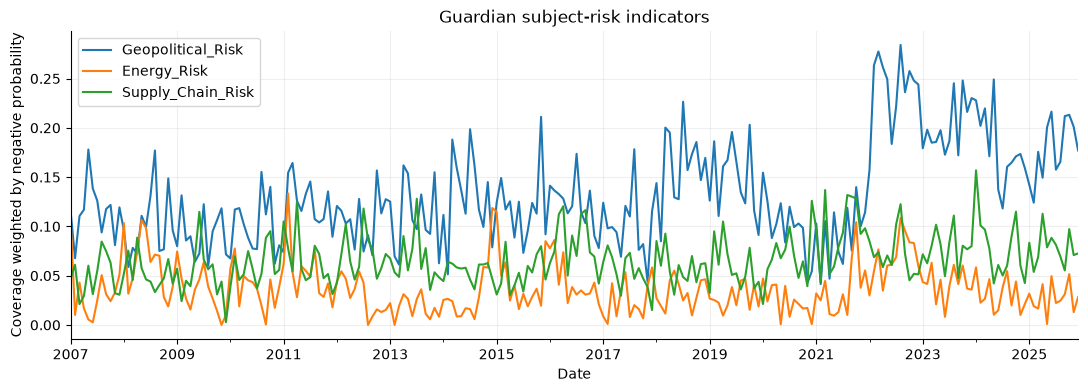

In [2]:
display(pd.Series({
    'First month': data.Date.min().date(),
    'Last month': data.Date.max().date(),
    'Months': len(data),
    'Guardian articles': int(data.Article_Count.sum()),
    'Scored test months': len(results['models'][0]['forecasts']),
}, name='EU-27 replication').to_frame())
data.set_index('Date')[['Geopolitical_Risk', 'Energy_Risk', 'Supply_Chain_Risk']].plot(
    figsize=(13, 4), title='Guardian subject-risk indicators')
plt.ylabel('Coverage weighted by negative probability')
plt.grid(alpha=.2)
plt.show()

## Out-of-sample forecast results

,model,family,rmse,mae,mean_error_actual_minus_forecast
0,AR-HMM(1) + all subject risks,AR-HMM,0.4522,0.3204,0.1496
1,AR-HMM(1) + supply-chain risk,AR-HMM,0.4547,0.3075,0.1434
2,AR-HMM(1) + lagged sentiment,AR-HMM,0.4614,0.3198,0.1755
3,AR-HMM(1) + energy risk,AR-HMM,0.4633,0.3255,0.1672
4,AR-HMM(1),AR-HMM,0.4658,0.3203,0.1791
5,MS-Variance AR(1) + energy risk,MS-Variance,0.4663,0.3287,0.1147
6,AR-HMM(1) + geopolitical risk,AR-HMM,0.4666,0.3309,0.1806
7,AR-HMM(1) + sentiment dispersion,AR-HMM,0.4696,0.3237,0.1890
8,AR(1) + all subject risks,AR,0.4760,0.3232,0.1512
9,MS-Variance AR(1) + supply-chain risk,MS-Variance,0.4782,0.3259,0.1181


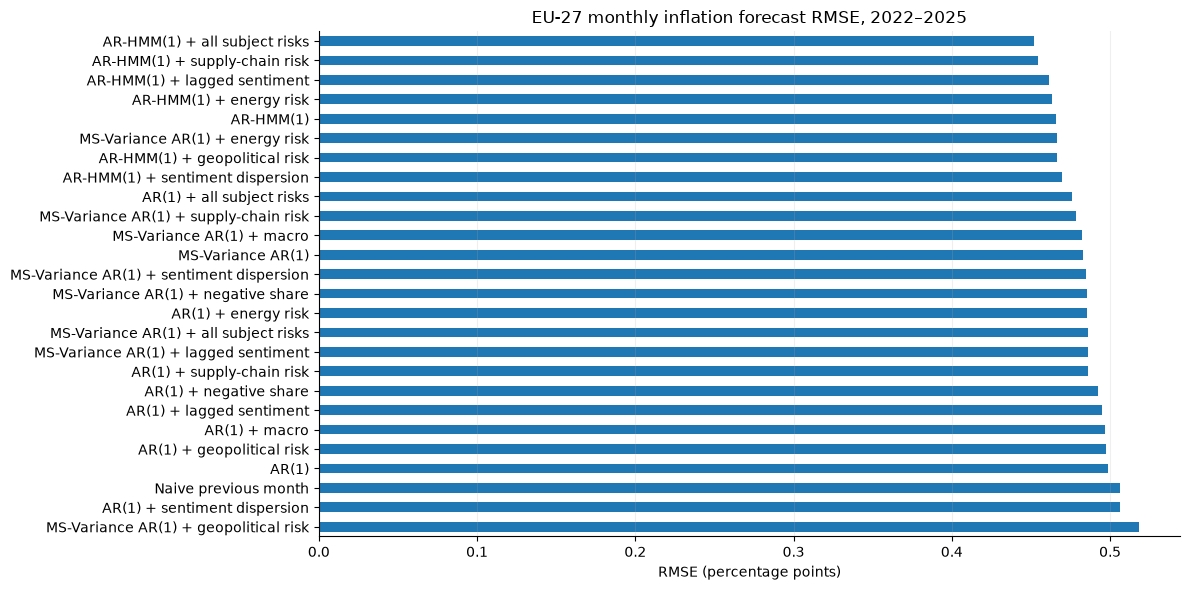

In [3]:
table = pd.DataFrame([{'model': item['model'], 'family': item['family'], **item['metrics']}
                      for item in results['models']]).sort_values('rmse').reset_index(drop=True)
display(table.round(4))
ordered = table.sort_values('rmse', ascending=False)
ordered.plot.barh(x='model', y='rmse', legend=False, figsize=(12, 6),
                  title='EU-27 monthly inflation forecast RMSE, 2022–2025')
plt.xlabel('RMSE (percentage points)')
plt.ylabel('')
plt.grid(axis='x', alpha=.2)
plt.tight_layout()
plt.show()

## Winner robustness

In [4]:
diagnostics = results['diagnostics']
seed_runs = pd.DataFrame(diagnostics['winner_initialization_robustness'])
display(pd.Series({
    'Winner': diagnostics['winner'],
    'RMSE range across five seeds': f"{seed_runs.rmse.min():.4f}–{seed_runs.rmse.max():.4f}",
    'Loss-test p-value versus AR(1)': diagnostics['newey_west_lag1_loss_test_pvalues']['AR(1)'],
    'Loss-test p-value versus AR-HMM(1)': diagnostics['newey_west_lag1_loss_test_pvalues']['AR-HMM(1)'],
}, name='Robustness').to_frame())

,Robustness
Winner,AR-HMM(1) + all subject risks
RMSE range across five seeds,0.4522–0.4523
Loss-test p-value versus AR(1),0.058468
Loss-test p-value versus AR-HMM(1),0.33431


## Best model versus AR benchmark

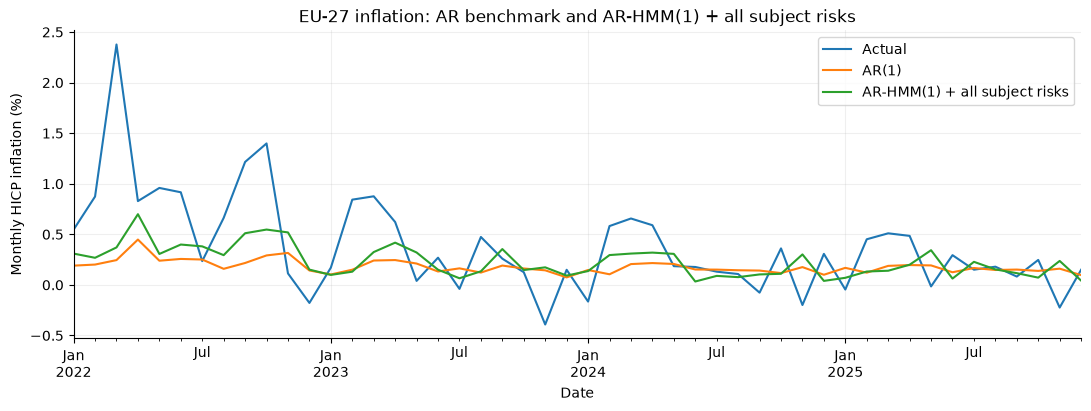

In [5]:
best_name = table.iloc[0].model
selected = [item for item in results['models'] if item['model'] in {'AR(1)', best_name}]
plot = None
for item in selected:
    frame = pd.DataFrame(item['forecasts'])
    frame['Date'] = pd.to_datetime(frame.Date)
    if plot is None:
        plot = frame[['Date', 'Actual']].set_index('Date')
    plot[item['model']] = frame.set_index('Date').Forecast
plot.plot(figsize=(13, 4), title=f'EU-27 inflation: AR benchmark and {best_name}')
plt.ylabel('Monthly HICP inflation (%)')
plt.grid(alpha=.2)
plt.show()

## Lag and hidden-state validation

In [6]:
selection = results['structure_validation']
validation = pd.DataFrame([{'model': item['model'], **item['metrics'], 'converged': item['converged']}
                           for item in selection['validation_candidates']]).sort_values('rmse')
display(validation.round(4))
display(pd.DataFrame([{'model': item['model'], **item['metrics']}
                      for item in selection['final_test']]).round(4))

,model,rmse,mae,mean_error_actual_minus_forecast,converged
1,"AR-HMM(1), 2 states",0.3775,0.2900,0.0283,True
5,"AR-HMM(2), 3 states",0.3813,0.2855,0.0358,True
2,"AR-HMM(1), 3 states",0.3844,0.2937,0.0725,True
9,"AR-HMM(1), 2 states, common AR",0.3862,0.2950,0.0283,True
0,AR(1),0.3895,0.2987,0.0256,True
4,"AR-HMM(2), 2 states",0.3898,0.3054,0.0664,True
10,"MS-Variance AR(1), 2 states",0.3932,0.2916,-0.0428,True
8,"AR-HMM(3), 3 states",0.3963,0.3034,0.0572,True
6,AR(3),0.3983,0.3029,0.0371,True
3,AR(2),0.3997,0.3030,0.0322,True


,model,rmse,mae,mean_error_actual_minus_forecast
0,"Selected AR-HMM(1), 2 states baseline",0.4658,0.3203,0.1791
1,"Selected AR-HMM(1), 2 states + all subject risks",0.4522,0.3204,0.1496


## Seasonally adjusted monthly inflation

fold,2007-2016 → 2017-2018,2007-2018 → 2019-2020,2007-2020 → 2021
model,,,
Seasonally adjusted AR(1),0.1732,0.1873,0.4014
Seasonally adjusted AR-HMM(1),0.1747,0.1885,0.3981
Seasonally adjusted AR-HMM(1) + all subject risks,0.1694,0.1894,0.3986


,model,rmse,mae,mean_error_actual_minus_forecast
2,Seasonally adjusted AR-HMM(1) + all subject risks,0.2400,0.1634,0.0288
1,Seasonally adjusted AR-HMM(1),0.2411,0.1610,0.0282
0,Seasonally adjusted AR(1),0.2414,0.1613,0.0260


,model,rmse,mae,mean_error_actual_minus_forecast
0,Seasonally adjusted AR(1),0.4331,0.3230,0.1596
2,Seasonally adjusted AR-HMM(1) + all subject risks,0.4396,0.3285,0.1724
1,Seasonally adjusted AR-HMM(1),0.4553,0.3493,0.1839


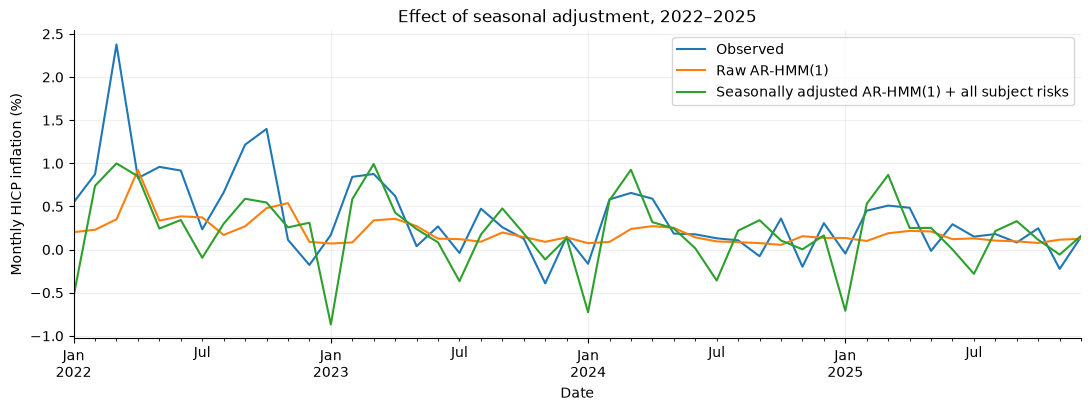

In [7]:
seasonal = results['seasonal_experiment']
rolling = seasonal['rolling_validation']
folds = pd.DataFrame([{'fold': fold['fold'], 'model': item['model'], **item['metrics']}
                      for fold in rolling['folds'] for item in fold['models']])
seasonal_validation = pd.DataFrame([{'model': item['model'], **item['metrics']}
                                    for item in rolling['combined_models']]).sort_values('rmse')
seasonal_test = pd.DataFrame([{'model': item['model'], **item['metrics']}
                              for item in seasonal['final_test']]).sort_values('rmse')
display(folds.pivot(index='model', columns='fold', values='rmse').round(4))
display(seasonal_validation.round(4))
display(seasonal_test.round(4))
raw = next(item for item in results['models'] if item['model'] == 'AR-HMM(1)')
adjusted = next(item for item in seasonal['final_test']
                if item['model'] == rolling['preferred_model'])
raw_forecast = pd.DataFrame(raw['forecasts']).assign(Date=lambda x: pd.to_datetime(x.Date)).set_index('Date')
adjusted_forecast = pd.DataFrame(adjusted['forecasts']).assign(Date=lambda x: pd.to_datetime(x.Date)).set_index('Date')
comparison = raw_forecast[['Actual']].rename(columns={'Actual': 'Observed'})
comparison['Raw AR-HMM(1)'] = raw_forecast.Forecast
comparison[adjusted['model']] = adjusted_forecast.Forecast
comparison.plot(figsize=(13, 4), title='Effect of seasonal adjustment, 2022–2025')
plt.ylabel('Monthly HICP inflation (%)')
plt.grid(alpha=.2)
plt.show()